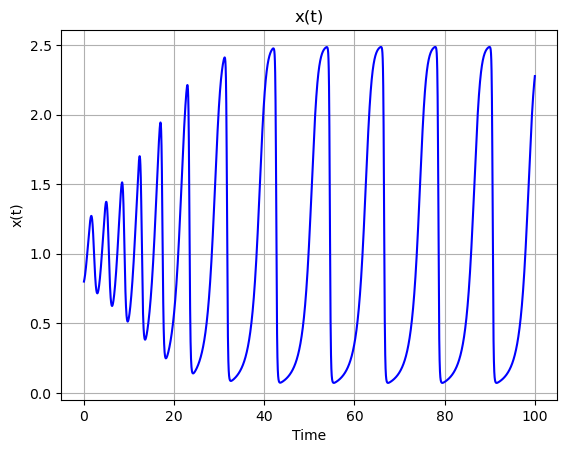

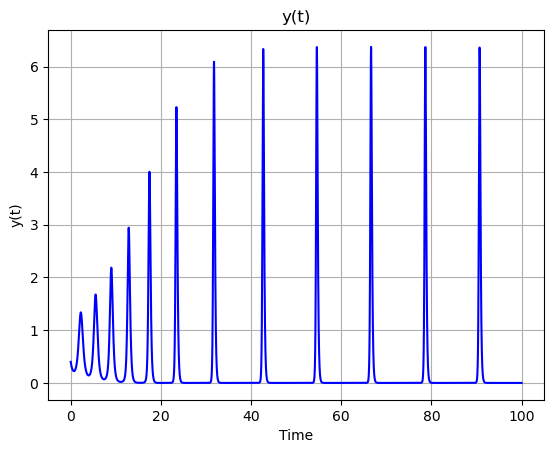

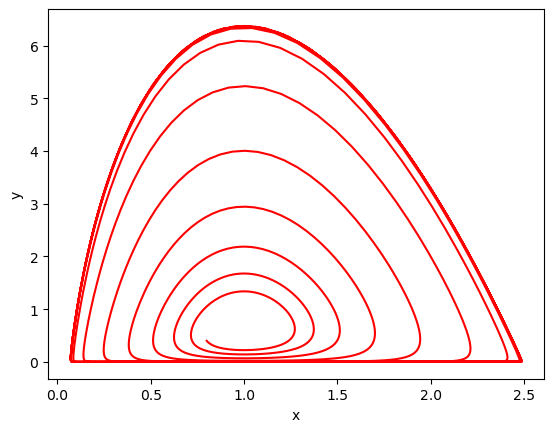

In [60]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

mu = 0.4
rho = 7

def sim(t, z):
    x, y = z

    dx = np.sqrt(x) * (x * (1 - mu*x) - y)
    dy = rho * (x - 1) * y

    return [dx, dy]
    
z0 = [0.8, 0.4]

t_span = (0, 100)
t_eval = np.linspace(0, 100, 5000)

sol = solve_ivp(
    sim, t_span, z0,
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)

t = sol.t
x = sol.y[0]
y = sol.y[1]

plt.figure()
plt.plot(t, x, 'blue')
plt.xlabel('Time')
plt.ylabel('x(t)')
plt.title('x(t)')
plt.grid()
plt.show()

plt.figure()
plt.plot(t, y, 'blue')
plt.xlabel('Time')
plt.ylabel('y(t)')
plt.title('y(t)')
plt.grid()
plt.show()

plt.figure()
plt.plot(x, y, 'red')
plt.xlabel('x')
plt.ylabel('y')
plt.show()


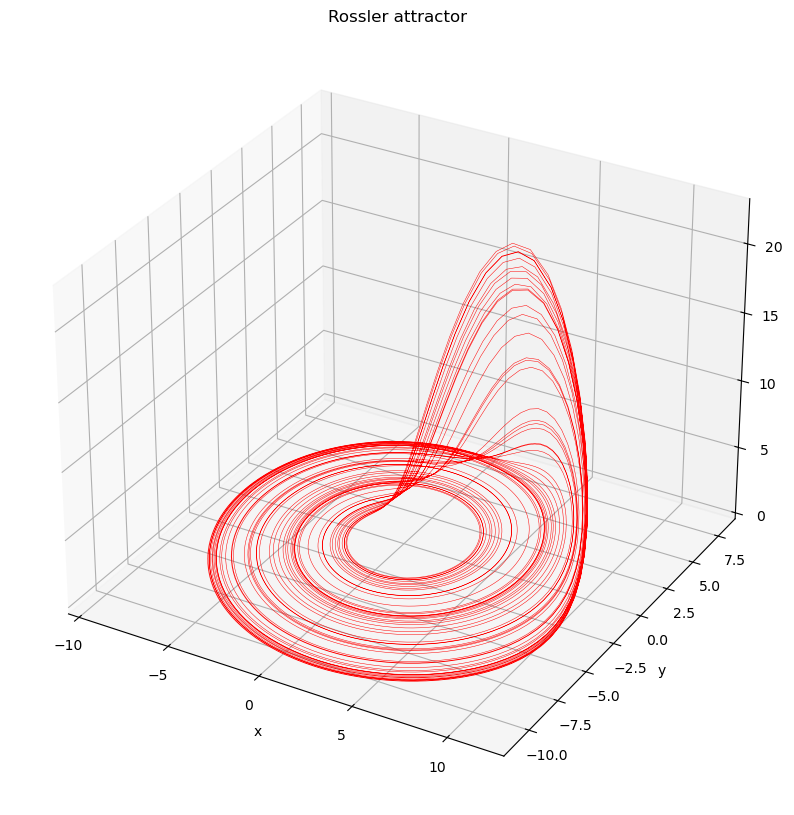

In [61]:
#part a
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a = 0.2
b = 0.2
c = 5.7

def rossler(t, u):
    x, y, z = u

    dx = -y - z
    dy = x + a*y
    dz = b + z*(x-c)

    return [dx, dy, dz]


u0 = [1, 2, 0]

sol = solve_ivp(
    rossler,
    [0, 500],
    u0,
    method='DOP853',
    rtol=1e-10,
    atol=1e-12,
    max_step=0.05,
    dense_output=True
)

t = sol.t
x, y, z = sol.y

mask = t >= 200

x = x[mask]
y = y[mask]
z = z[mask]

fig = plt.figure(figsize=(10, 12))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, color='red', linewidth=0.35)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Rossler attractor')

plt.show()

In [65]:
#part b
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a = 0.2
b = 0.2
c = 5.7

def rossler(t, u):

    x, y, z = u

    dx = -y - z
    dy = x + a*y
    dz = b + z*(x-c)

    return [dx, dy, dz]


u0 = [0.0, 0.0, 1.0]


transient_time = 500

transient = solve_ivp(
    rossler,
    [0, transient_time],
    u0,
    method='DOP853',
    rtol=1e-10,
    atol=1e-12,
    max_step=0.01
)

u_start = transient.y[:, -1]


def poincareE(t, u):

    return u[1]  

poincareE.direction = -1

poincareE.terminal = False



final_time = 3000

sol = solve_ivp(
    rossler,
    [transient_time, final_time],
    u_start,
    method='DOP853',
    rtol=1e-10,
    atol=1e-12,
    max_step=0.05,
    events=poincareE
)


crossings = sol.y_events[0]

crossings = crossings[crossings[:, 0] < 0]

xn = crossings[:, 0]
zn = crossings[:, 2]

if len(xn) < 200:
    raise ValueError("not enough 200 points, error!")


N = 200
xn = xn[:N]
zn = zn[:N]


print("intersection:")

for n in range(N):
    print(
        f"{n+1}: "
        f"x={xn[n]:.4f}, "
        f"z={zn[n]:.4f}"
    )



intersection:
1: x=-4.4533, z=0.0198
2: x=-7.9070, z=0.0147
3: x=-5.4133, z=0.0181
4: x=-8.9822, z=0.0137
5: x=-2.8564, z=0.0241
6: x=-5.2310, z=0.0184
7: x=-8.8467, z=0.0138
8: x=-3.1169, z=0.0230
9: x=-5.6938, z=0.0176
10: x=-9.0968, z=0.0136
11: x=-2.6611, z=0.0256
12: x=-4.8812, z=0.0190
13: x=-8.4825, z=0.0141
14: x=-3.9335, z=0.0209
15: x=-7.0939, z=0.0157
16: x=-7.4866, z=0.0152
17: x=-6.5218, z=0.0164
18: x=-8.5791, z=0.0140
19: x=-3.7037, z=0.0214
20: x=-6.7106, z=0.0162
21: x=-8.2742, z=0.0144
22: x=-4.4524, z=0.0198
23: x=-7.9055, z=0.0147
24: x=-5.4171, z=0.0181
25: x=-8.9846, z=0.0137
26: x=-2.8521, z=0.0242
27: x=-5.2234, z=0.0184
28: x=-8.8401, z=0.0138
29: x=-3.1303, z=0.0230
30: x=-5.7175, z=0.0176
31: x=-9.1005, z=0.0136
32: x=-2.6551, z=0.0256
33: x=-4.8706, z=0.0190
34: x=-8.4697, z=0.0142
35: x=-3.9647, z=0.0208
36: x=-7.1450, z=0.0156
37: x=-7.3681, z=0.0154
38: x=-6.8241, z=0.0160
39: x=-8.0621, z=0.0146
40: x=-5.0029, z=0.0188
41: x=-8.6225, z=0.0140
42: x=-3.60

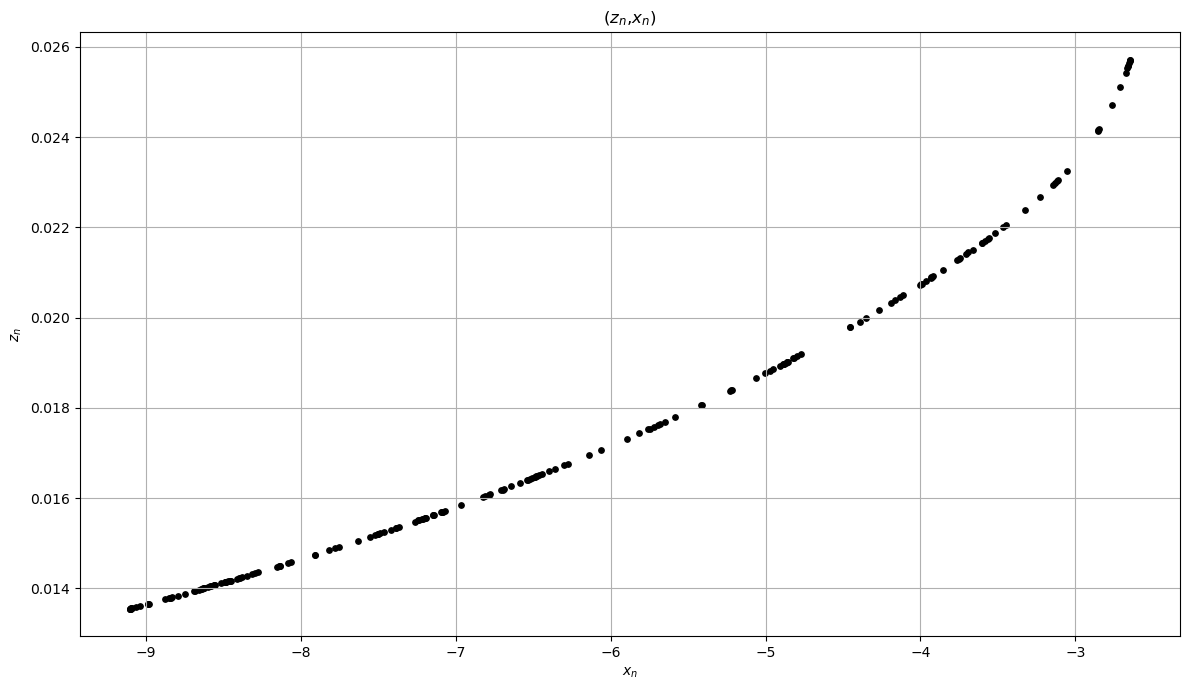

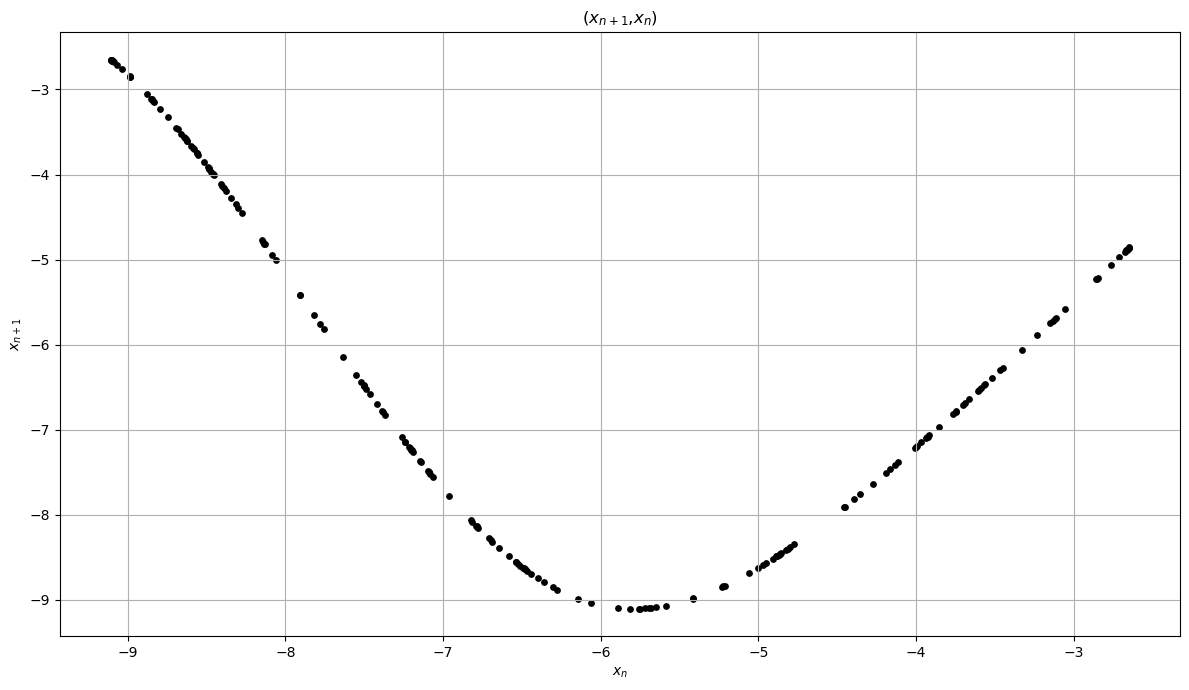

In [62]:
#part c

plt.figure(figsize=(12, 7))

plt.scatter(xn, zn, color='black', s=15)

plt.xlabel(r'$x_n$')
plt.ylabel(r'$z_n$')

plt.title(r'($z_n$,$x_n$)')

plt.grid(True)
plt.tight_layout()
plt.show()



plt.figure(figsize=(12, 7))

plt.scatter(
    xn[:-1],
    xn[1:],
    color='black',
    s=15
)

plt.xlabel(r'$x_n$')
plt.ylabel(r'$x_{n+1}$')

plt.title(r'($x_{n+1}$,$x_n$)')

plt.grid(True)
plt.tight_layout()
plt.show()


Q(x) = 
+2.399128933399e+00 x^0 +4.373308221440e+00 x^1 +3.579277105505e+00 x^2 +1.711745743505e+00 x^3 +5.292533635859e-01 x^4 +1.105439951898e-01 x^5 +1.579960216501e-02 x^6 +1.526357169381e-03 x^7 +9.542907873781e-05 x^8 +3.488339559750e-06 x^9 +5.664373136392e-08 x^10 

P(x) = 
+3.391333420186e+02 x^0 +6.949204210986e+02 x^1 +6.212133786226e+02 x^2 +3.212698488711e+02 x^3 +1.060643983778e+02 x^4 +2.333645642440e+01 x^5 +3.463359558624e+00 x^6 +3.422876003391e-01 x^7 +2.157171282519e-02 x^8 +7.837151815760e-04 x^9 +1.248175570456e-05 x^10 


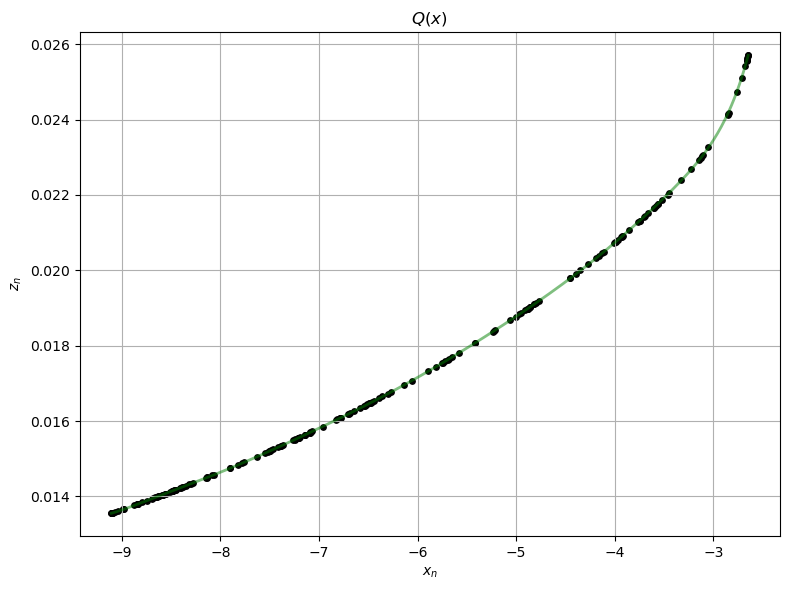

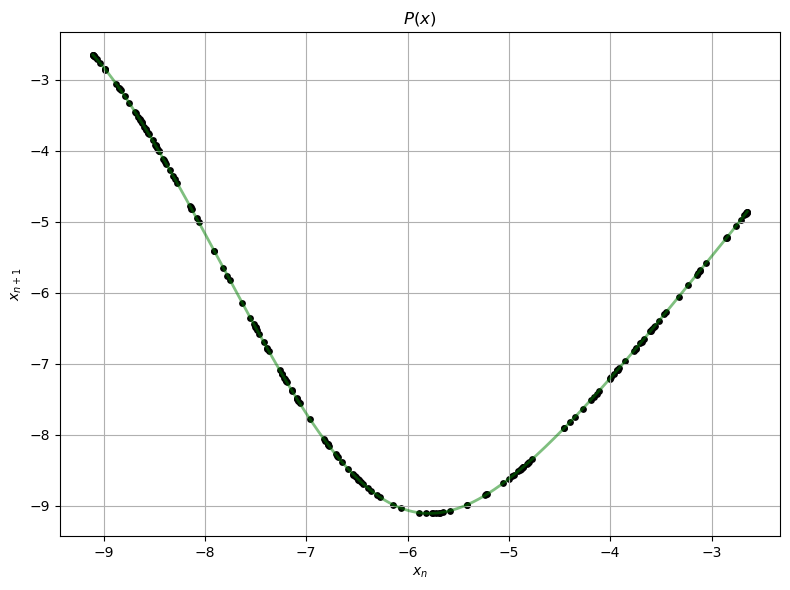

In [47]:
#part d

degree = 10


Q = np.polynomial.Polynomial.fit(
    xn,
    zn,
    degree
)

Q_standard = Q.convert()



print("\nQ(x) = ")

for i, coefficient in enumerate(Q_standard.coef):
    print(f"{coefficient:+.12e} x^{i}", end=" ")

print()



P = np.polynomial.Polynomial.fit(
    xn[:-1],
    xn[1:],
    degree
)

P_standard = P.convert()


print("\nP(x) = ")

for i, coefficient in enumerate(P_standard.coef):
    print(f"{coefficient:+.12e} x^{i}", end=" ")

print()



xplot = np.linspace(
    min(xn),
    max(xn),
    500
)


# ------------------------------------------
# STEP 4: Plot Q(x)
# ------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    xn,
    zn,
    color='black',
    s=15,
    
)

plt.plot(
    xplot,
    Q(xplot),
    color='green',
    alpha=0.5,
    linewidth=2,
    
)

plt.xlabel(r'$x_n$')
plt.ylabel(r'$z_n$')

plt.title(r'$Q(x)$')

plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))

plt.scatter(
    xn[:-1],
    xn[1:],
    color='black',
    s=15,

)

plt.plot(
    xplot,
    P(xplot),
    color='green',
    alpha=0.5,
    linewidth=2,

)

plt.xlabel(r'$x_n$')
plt.ylabel(r'$x_{n+1}$')

plt.title(r'$P(x)$')


plt.grid(True)
plt.tight_layout()
plt.show()







In [51]:
#part e

from scipy.optimize import brentq

# Define the polynomial iteration
def iterate_P(x, k):
    for _ in range(k):
        x = float(P(x))
    return x


# Define periodic equation
def periodic_equation(x, k):
    return iterate_P(x, k) - x


# Search interval
xmin = min(xn)
xmax = max(xn)

# Find roots numerically
def find_roots(k):

    grid = np.linspace(xmin, xmax, 20000)

    values = np.array([
        periodic_equation(x, k) for x in grid
    ])

    roots = []

    for i in range(len(grid)-1):

        if not np.isfinite(values[i]) or not np.isfinite(values[i+1]):
            continue

        if values[i] * values[i+1] < 0:

            root = brentq(
                lambda x: periodic_equation(x, k),
                grid[i],
                grid[i+1]
            )

            if not any(abs(root-r) < 1e-6 for r in roots):
                roots.append(root)

    return roots


# Find candidate roots
roots1 = find_roots(1)
roots2 = find_roots(2)
roots3 = find_roots(3)


# Remove lower-period solutions
def valid_period(root, k):

    x = root

    for j in range(1, k+1):

        x = float(P(x))

        if not np.isfinite(x) or not xmin <= x <= xmax:
            return False

        if j < k and abs(x-root) < 1e-7:
            return False

    return abs(x-root) < 1e-7


period1 = [r for r in roots1 if valid_period(r, 1)]
period2 = [r for r in roots2 if valid_period(r, 2)]
period3 = [r for r in roots3 if valid_period(r, 3)]


# Group points belonging to the same orbit
def group_orbits(roots, k):

    orbits = []

    for root in roots:

        orbit = [root]
        x = root

        for _ in range(k-1):
            x = float(P(x))
            orbit.append(x)

        duplicate = any(
            max(min(abs(a-b) for b in existing) for a in orbit) < 1e-5
            for existing in orbits
        )

        if not duplicate:
            orbits.append(orbit)

    return orbits


orbits1 = group_orbits(period1, 1)
orbits2 = group_orbits(period2, 2)
orbits3 = group_orbits(period3, 3)


# Print periodic orbit coordinates
def print_orbits(orbits, k):

    print(f"\n k{k}:")

    for i, orbit in enumerate(orbits, 1):

        print(f"orbit{i}")

        for j, x in enumerate(orbit, 1):

            z = float(Q(x))

            print(
                f"({x:.4f}, 0, {z:.4f})"
            )


print_orbits(orbits1, 1)
print_orbits(orbits2, 2)
print_orbits(orbits3, 3)



 k1:
orbit1
(-7.2116, 0, 0.0155)

 k2:
orbit1
(-8.1939, 0, 0.0144)
(-4.6582, 0, 0.0194)

 k3:
orbit1
(-8.9449, 0, 0.0137)
(-2.9233, 0, 0.0238)
(-5.3522, 0, 0.0182)
orbit2
(-8.6384, 0, 0.0140)
(-3.5673, 0, 0.0218)
(-6.4783, 0, 0.0165)


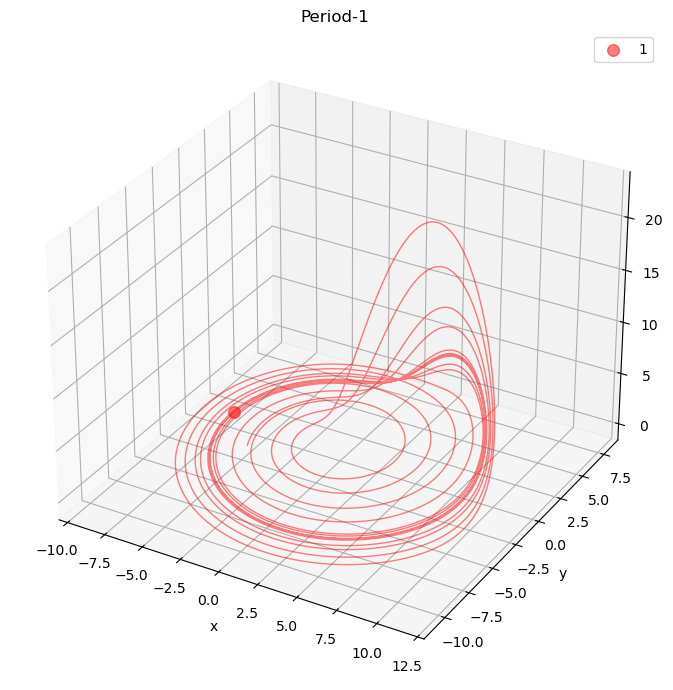

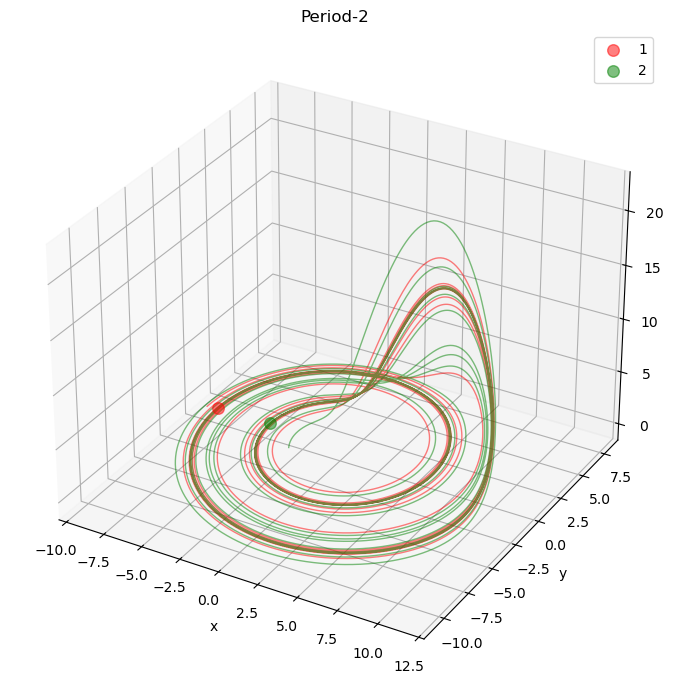

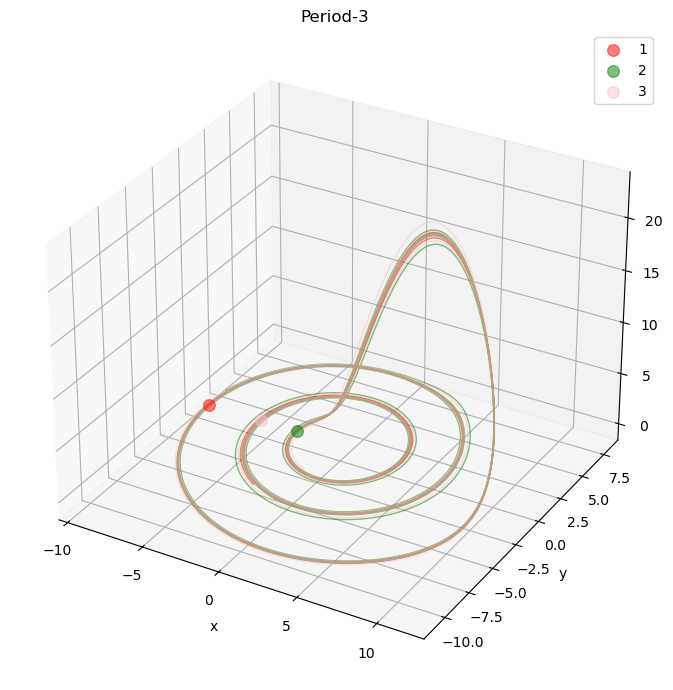

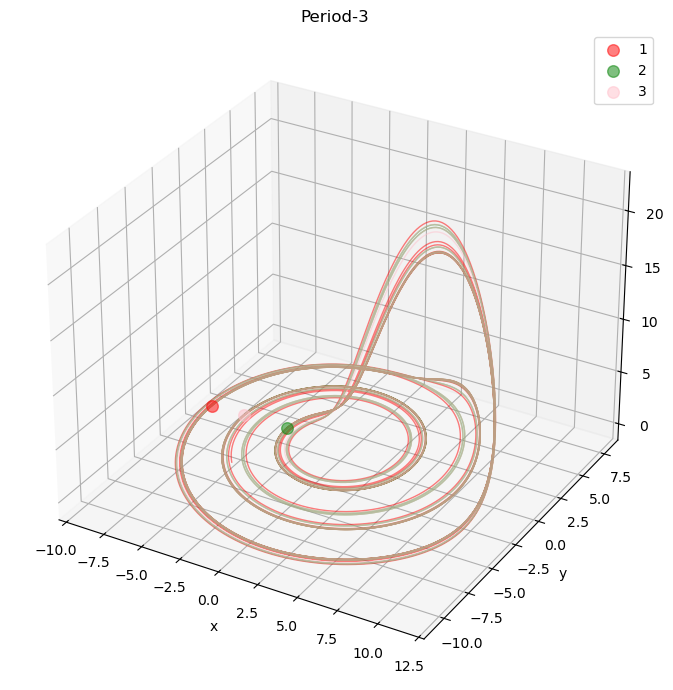

In [56]:
# part d
from mpl_toolkits.mplot3d import Axes3D

def plot_periodic_orbit(orbit, period):

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')

    colors = ['red', 'green', 'pink']

    for i, x in enumerate(orbit):

        z = float(Q(x))

        u0 = [x, 0.0, z]

        sol_orbit = solve_ivp(
            rossler,
            [0, 100],
            u0,
            method='DOP853',
            rtol=1e-12,
            atol=1e-14,
            max_step=0.01
        )

        ax.plot(
            sol_orbit.y[0],
            sol_orbit.y[1],
            sol_orbit.y[2],
            color=colors[i % 3],
            alpha=0.5,
            linewidth=1
        )

        ax.scatter(
            x, 0, z,
            color=colors[i % 3],
            alpha=0.5,
            s=70,
            label=f'{i+1}'
        )

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

    ax.set_title(f'Period-{period}')

    ax.legend()
    plt.tight_layout()
    plt.show()

#p1
for orbit in orbits1:
    plot_periodic_orbit(orbit, 1)
#p2
for orbit in orbits2:
    plot_periodic_orbit(orbit, 2)
#p3
for orbit in orbits3:
    plot_periodic_orbit(orbit, 3)